# Standard ConvNeXt fine-tuning

The head-only run gave us a useful fold-0 reference. Here we load that trained five-label head, unfreeze the original ConvNeXt backbone, and fine-tune the complete model without adding a custom block. This is the control for the later architectural comparison.

This is an eight-epoch control, shortened after a real T4 timing probe put the original ten-epoch plan beyond our five-hour gate. The first *protected* epoch still measures checkpoint and optional Drive-backup time; if its eight-epoch projection exceeds five hours, the run stops for another decision. Early stopping may finish sooner.

Run the cells from top to bottom. By default they inspect the data but do not download weights, train, write results, or build a submission. A fold-0 score is screening evidence, not five-fold cross-validation or a public leaderboard score. There is no Kaggle upload step.


In [ ]:
from __future__ import annotations

import importlib
import os
import platform
import random
import re
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch

RUN_TRAINING = os.environ.get('STAGE2_RUN_TRAINING', '0') == '1'
EVAL_CHECKPOINT = os.environ.get('STAGE2_EVAL_CHECKPOINT')
EVAL_RUN_RECORD = os.environ.get('STAGE2_EVAL_RUN_RECORD')
SMOKE_TEST = os.environ.get('STAGE2_SMOKE_TEST', '1') == '1'
PROFILE_ONLY = os.environ.get('STAGE2_PROFILE_ONLY', '0') == '1'
BACKUP_TO_DRIVE = os.environ.get('STAGE2_BACKUP_TO_DRIVE', '0') == '1'
DRIVE_FOLDER_NAME = os.environ.get('STAGE2_DRIVE_FOLDER_NAME', 'AI301-stage2')
DRIVE_ROOT = (Path('/content/drive/MyDrive') / DRIVE_FOLDER_NAME).resolve()
ALLOW_WEIGHT_DOWNLOAD = os.environ.get('STAGE2_ALLOW_WEIGHT_DOWNLOAD', '0') == '1'
USE_WANDB = os.environ.get('STAGE2_USE_WANDB', '1') == '1'
REMOVE_RUNTIME_ENV_AFTER_LOAD = os.environ.get('STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD', '0') == '1'
WANDB_MODE = 'online'
WANDB_PROJECT = 'ai301-stage2'
BUILD_SUBMISSION = False
BUILD_GRADCAM = True  # Only runs after a completed training run or verified checkpoint evaluation.
SUBMIT_TO_KAGGLE = False  # No submission API call exists in this notebook.

MODEL_NAME = 'hf-hub:timm/convnext_base.fb_in22k_ft_in1k_384@2b2698d86523262ca8065d0957c7f80d963bb43f'
HEAD_RUN_ID = 'convnext_head_fold0_seed42_colab'
RUN_ID = os.environ.get('STAGE2_RUN_ID', 'convnext_standard_fold0_seed42')
SEED = 42
VALIDATION_FOLD = 0
THRESHOLD = 0.25
IMAGE_SIZE = 384
BATCH_SIZE = 2
EFFECTIVE_BATCH_SIZE = 16
MAX_EPOCHS = 8
PATIENCE = 3
MAX_RUN_HOURS = 5.0
BACKBONE_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 0
PRECISION = '32-true'

if EFFECTIVE_BATCH_SIZE % BATCH_SIZE:
    raise ValueError('Effective batch size must be divisible by physical batch size.')
if RUN_TRAINING and EVAL_CHECKPOINT:
    raise ValueError('Choose training or an existing checkpoint, not both.')
if bool(EVAL_CHECKPOINT) != bool(EVAL_RUN_RECORD):
    raise ValueError('Checkpoint evaluation needs both STAGE2_EVAL_CHECKPOINT and STAGE2_EVAL_RUN_RECORD.')
if PROFILE_ONLY and (not RUN_TRAINING or SMOKE_TEST):
    raise ValueError('Profile-only mode requires training enabled and smoke mode disabled.')
if BACKUP_TO_DRIVE and not RUN_TRAINING:
    raise ValueError('Drive backup is for a training run.')
if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9._-]{0,79}', RUN_ID):
    raise ValueError('STAGE2_RUN_ID must be a single, safe run name.')
if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9._ -]{0,79}', DRIVE_FOLDER_NAME):
    raise ValueError('STAGE2_DRIVE_FOLDER_NAME must be one folder name (letters, numbers, spaces, dots, underscores or hyphens).')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {DEVICE}; training: {RUN_TRAINING}; saved checkpoint: {bool(EVAL_CHECKPOINT)}; smoke test: {SMOKE_TEST}; profile only: {PROFILE_ONLY}; Drive backup: {BACKUP_TO_DRIVE}')


Device: cuda; training: True; saved checkpoint: False; smoke test: False; profile only: False; Drive backup: True


## Use the same split as before

The validation notebook already assigned every image to one of five folds. We check that `folds.csv` still matches the seed-42 stratified split, then join it to the labels by image ID. This keeps our model comparisons on the same held-out images. Stratification uses the five-label combinations; one combination has only four images, so it cannot appear in every fold. Before training, we decode every training and validation JPEG to catch missing or damaged files while recovery is still cheap. Evaluation checks its validation images; test images are checked only when building a submission.

For the CNN, we keep the whole photo, resize it to fit inside a 384-pixel square, and pad the rest with the checkpoint's mean colour. Training images may be flipped horizontally; validation and test images are left alone. We use the pretrained checkpoint's RGB mean and standard deviation, not newly calculated dataset statistics. ConvNeXt's own LayerNorm stays in place; no BatchNorm or other new normalization layer is added. The old embedding baseline used different preprocessing, which matters when we compare scores.

In [ ]:
start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from stage2.experiment import LABEL_COLUMNS, ImageDataset, form_submission, preflight_images, read_csv, score_probabilities, split_rows, verify_saved_stratification, write_probabilities, write_run_record, write_submission
from stage2.train import predict_probabilities
from stage2 import finetune
importlib.reload(finetune)  # Colab CLI may reuse a kernel from an earlier run.
from stage2.finetune import DriveRunBackup, FineTuneClassifier, TimedBudgetCheckpoint, copy_verified, load_trained_head

from stage2 import run_records, diagnostics as training_diagnostics
importlib.reload(run_records)
importlib.reload(training_diagnostics)
from stage2.run_records import file_sha256, record_failures, validate_evaluation_record
from stage2.diagnostics import TrainingDiagnostics, plot_gradient_flow

run_name = RUN_ID + ('_evaluation' if EVAL_CHECKPOINT else '_smoke' if SMOKE_TEST else '')
run_dir = ROOT / 'artifacts' / run_name if RUN_TRAINING or EVAL_CHECKPOINT else None
if run_dir is not None:
    run_dir.mkdir(parents=True, exist_ok=False)
failure_configuration = {'run_id': RUN_ID, 'experiment': '01_convnext_standard', 'fold': VALIDATION_FOLD, 'seed': SEED, 'model_name': MODEL_NAME, 'smoke_test': SMOKE_TEST, 'profile_only': PROFILE_ONLY, 'device': str(DEVICE), 'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'weight_decay': WEIGHT_DECAY, 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'precision': PRECISION, 'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'threshold': THRESHOLD, 'image_size': IMAGE_SIZE}
def backup_failure(path: Path) -> None:
    if BACKUP_TO_DRIVE and Path('/content/drive/MyDrive').is_dir() and DRIVE_ROOT.is_relative_to('/content/drive/MyDrive'):
        copy_verified(path, DRIVE_ROOT / '01_convnext_standard' / run_name / 'failure.json')

DATA_DIR = ROOT / 'data'
with record_failures(run_dir, failure_configuration, 'data', backup_failure):
    combination_counts = verify_saved_stratification(DATA_DIR, ROOT / 'folds.csv', SEED)
    train_rows, validation_rows = split_rows(DATA_DIR, ROOT / 'folds.csv', VALIDATION_FOLD)
    test_rows = read_csv(DATA_DIR / 'test.csv', ('image_id',))
    sample_rows = read_csv(DATA_DIR / 'sample_submission.csv', ('image_id', *LABEL_COLUMNS))
    if {row['image_id'] for row in test_rows} != {row['image_id'] for row in sample_rows}:
        raise ValueError('test.csv and sample_submission.csv have different image IDs.')
    if RUN_TRAINING:
        preflight_images([*train_rows, *validation_rows], DATA_DIR / 'train')
    elif EVAL_CHECKPOINT:
        preflight_images(validation_rows, DATA_DIR / 'train')
    if BUILD_SUBMISSION:
        preflight_images(test_rows, DATA_DIR / 'test')
print(f'{len(train_rows):,} train, {len(validation_rows):,} validation, {len(test_rows):,} test images')
print('Saved combination-stratified folds verified:', combination_counts)
print('Positive validation labels:', {label: sum(int(row[label]) for row in validation_rows) for label in LABEL_COLUMNS})

9,808 train, 2,452 validation, 18,673 test images
Saved combination-stratified folds verified: {'00000': 2162, '01000': 4984, '01001': 37, '10000': 4989, '10010': 32, '10100': 42, '10110': 10, '11101': 4}
Positive validation labels: {'Cat': 1015, 'Dog': 1004, 'Moris': 10, 'Motya': 9, 'Biatrix': 8}


## Connect W&B when training starts

For a local run, put `WANDB_API_KEY` in the repo's ignored `.env` file or export it before launching Jupyter. The existing `WB_API_KEY` name also works. In Colab, add a `WANDB_API_KEY` secret and grant the notebook access. The key is read only when online training is enabled; it is never printed or saved in the notebook.

In [ ]:
def ensure_wandb_key() -> None:
    key = os.environ.get('WANDB_API_KEY') or os.environ.get('WB_API_KEY')
    env_file = ROOT / '.env'
    if not key and env_file.is_file():
        for line in env_file.read_text().splitlines():
            name, separator, value = line.partition('=')
            if separator and name.strip() in {'WANDB_API_KEY', 'WB_API_KEY'}:
                key = value.strip().strip("\"'")
                if key:
                    break
    if key:
        os.environ['WANDB_API_KEY'] = key
        if REMOVE_RUNTIME_ENV_AFTER_LOAD and env_file.is_file() and ROOT.is_relative_to('/content'):
            env_file.unlink()
            print('Removed the temporary Colab credential file.')
        return
    try:
        from google.colab import userdata
    except ImportError:
        raise RuntimeError('Set WANDB_API_KEY in the repo .env file or environment.') from None
    try:
        secret = userdata.get('WANDB_API_KEY')
    except Exception as error:
        raise RuntimeError('Add WANDB_API_KEY to Colab Secrets and grant this notebook access.') from error
    if not secret:
        raise RuntimeError('The WANDB_API_KEY Colab Secret is empty.')
    os.environ['WANDB_API_KEY'] = secret

if RUN_TRAINING and USE_WANDB and WANDB_MODE == 'online':
    with record_failures(run_dir, failure_configuration, 'credentials', backup_failure):
        ensure_wandb_key()
    print('W&B online credential is available (value hidden).')
else:
    print('W&B credential check skipped until online training is enabled.')

Removed the temporary Colab credential file.
W&B online credential is available (value hidden).


## Load the same backbone and trained head

The saved file contains the final linear classifier's weights and bias, not the optimizer or all of timm's head modules. We recreate the exact pretrained backbone, install those parameters with a strict shape-and-key check, and then leave **all** parameters trainable, including the existing LayerNorm. This head was trained on folds 1–4 and selected on fold 0; using it for another held-out fold would contaminate that fold's evaluation.

The model produces five logits in the fixed label order. BCEWithLogitsLoss handles each label independently during training; sigmoid turns the logits into probabilities for validation and submission formation.


In [ ]:
if RUN_TRAINING or EVAL_CHECKPOINT:
    if not ALLOW_WEIGHT_DOWNLOAD:
        os.environ['HF_HUB_OFFLINE'] = '1'
    import timm
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    from torch.utils.data import DataLoader

    L.seed_everything(SEED, workers=True)
    with record_failures(run_dir, failure_configuration, 'model', backup_failure):
        network = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABEL_COLUMNS))
        preprocessing = timm.data.resolve_model_data_config(network)
        if preprocessing['input_size'][-1] != IMAGE_SIZE:
            raise ValueError(f"Checkpoint expects {preprocessing['input_size']}, not {IMAGE_SIZE}px.")
        head_path = ROOT / 'experiments' / '00_shared_head' / 'checkpoints' / f'{HEAD_RUN_ID}_head.pt'
        load_trained_head(network, head_path)
    for parameter in network.parameters():
        parameter.requires_grad_(True)
    train_data = ImageDataset(train_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'], horizontal_flip=True)
    validation_data = ImageDataset(validation_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
    train_generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_data, shuffle=True, generator=train_generator, **loader_options)
    validation_loader = DataLoader(validation_data, shuffle=False, **loader_options)
    if RUN_TRAINING:
        _, image, targets = train_data[0]
        assert image.shape == (3, IMAGE_SIZE, IMAGE_SIZE) and targets.shape == (5,)
    print('Normalization:', preprocessing['mean'], preprocessing['std'])
    print('Trainable parameters:', sum(p.numel() for p in network.parameters() if p.requires_grad))
    run_configuration = {
        'fold': VALIDATION_FOLD, 'seed': SEED,
        'model': {'name': MODEL_NAME, 'variant': 'standard', 'pretrained_checkpoint': MODEL_NAME, 'initial_head_checkpoint': str(head_path.relative_to(ROOT)), 'initial_head_sha256': file_sha256(head_path)},
        'data': {'image_size': IMAGE_SIZE, 'transform': 'mean-colour letterbox, bicubic, checkpoint normalization; train horizontal flip p=0.5', 'fold_file': 'folds.csv', 'fold_sha256': file_sha256(ROOT / 'folds.csv'), 'label_columns': list(LABEL_COLUMNS), 'mean': list(preprocessing['mean']), 'std': list(preprocessing['std'])},
        'training': {'optimizer': f'AdamW(backbone_lr={BACKBONE_LR}, head_lr={HEAD_LR}, weight_decay={WEIGHT_DECAY} except bias/norm, betas=(0.9, 0.999))', 'scheduler': 'one epoch step warmup then cosine to 0.1 peak', 'loss': 'BCEWithLogitsLoss', 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'precision': PRECISION, 'stage_policy': 'full backbone and classifier trainable', 'checkpoint_selection': 'best validation macro F1 at 0.25', 'gradient_clip_norm': 1.0},
        'metrics': {'threshold': THRESHOLD},
    }
    failure_configuration.update(run_configuration)
    with record_failures(run_dir, failure_configuration, 'checkpoint_provenance', backup_failure):
        source_run_record = validate_evaluation_record(Path(EVAL_RUN_RECORD).resolve(), Path(EVAL_CHECKPOINT).resolve(), run_configuration, experiment='01_convnext_standard') if EVAL_CHECKPOINT else None
        if source_run_record is not None and source_run_record['run_id'] == RUN_ID:
            raise ValueError('Use a new STAGE2_RUN_ID for checkpoint evaluation.')
else:
    print('Model loading skipped.')


INFO: Seed set to 42


INFO:lightning.fabric.utilities.seed:Seed set to 42


Normalization: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]
Trainable parameters: 87571589


## Check the training path, then time the control

There are three training modes, each with a fresh `STAGE2_RUN_ID`. Keep `STAGE2_SMOKE_TEST=1` for eight training and four validation batches; this checks backward propagation, logging and checkpoint reload, but its partial score is **not** a result. Set `STAGE2_SMOKE_TEST=0` and `STAGE2_PROFILE_ONLY=1` for one complete timing epoch. It uses the eight-epoch optimizer schedule but stops after that epoch. Set both flags to `0` for the full control; it still stops after epoch one if the protected eight-epoch projection exceeds five hours. Training starts only with `STAGE2_RUN_TRAINING=1`.

The unchanged architecture uses AdamW with backbone LR `1e-5` and final-classifier LR `1e-4`. Weight decay `0.01` applies to eligible weights, not biases or normalization parameters. A step-based scheduler warms the rates during epoch one and then cosine-decays them to 10% of their peaks by epoch eight. The physical batch is two, with gradient accumulation to an effective batch of 16; this does not alter LayerNorm or simulate a BatchNorm batch of 16. We clip gradient norm at 1.0. Lightning records losses, fixed-threshold F1, AP, and gradient norms in CSV and W&B. The model file and photos are not sent to W&B.

Drive backup is optional and off by default. For Colab, mount Drive first, set `STAGE2_BACKUP_TO_DRIVE=1`, and choose `STAGE2_DRIVE_FOLDER_NAME` (default `AI301-stage2`). For example, `STAGE2_DRIVE_FOLDER_NAME=AI301-convnext-controls` writes under `/content/drive/MyDrive/AI301-convnext-controls/01_convnext_standard/<run-id>/`. Give each run a unique ID: existing Drive files are never overwritten. The notebook checks the mount with a small write before training.

After each complete epoch, it copies a full resume checkpoint (model, optimizer and scheduler), the best evaluation checkpoint when it changes, and a manifest. It verifies each copy before exposing its final filename. Curves, layer-gradient measurements, and completed-run results are copied when available. If training or evaluation fails, a small local failure record keeps the phase and exception type without saving the exception message; the notebook also tries to copy it to Drive when that backup is enabled and mounted. Leave Drive space for multiple large checkpoints; a failed copy stops the run. Fresh-VM resume is not yet automated, and the CLI output-bearing notebook must still be saved separately.


In [ ]:
if RUN_TRAINING:
    drive_backup = None
    with record_failures(run_dir, failure_configuration, 'storage_setup', backup_failure):
        if BACKUP_TO_DRIVE:
            if not ROOT.is_relative_to('/content') or not Path('/content/drive/MyDrive').is_dir():
                raise RuntimeError('Mount Google Drive on this Colab runtime before training.')
            if not DRIVE_ROOT.is_relative_to('/content/drive/MyDrive'):
                raise ValueError('The Drive folder must remain under /content/drive/MyDrive.')
            drive_backup = DriveRunBackup(run_dir, DRIVE_ROOT / '01_convnext_standard' / run_name)
        if drive_backup is not None:
            probe = run_dir / 'drive_probe.txt'
            probe.write_text(f'{run_name} Drive write check\n')
            copy_verified(probe, drive_backup.drive_dir / probe.name)
            print('Drive backup available:', drive_backup.drive_dir)
    module = FineTuneClassifier(network, BACKBONE_LR, HEAD_LR, WEIGHT_DECAY, THRESHOLD)
    checkpoint_options = dict(dirpath=run_dir / 'checkpoints', filename='best', monitor='val_macro_f1', mode='max', save_top_k=1, save_weights_only=True)
    checkpoint = ModelCheckpoint(**checkpoint_options) if SMOKE_TEST else TimedBudgetCheckpoint(**checkpoint_options, maximum_hours=MAX_RUN_HOURS, profile_only=PROFILE_ONLY, epoch_backup=drive_backup.save_epoch if drive_backup else None)
    diagnostics = TrainingDiagnostics(run_dir / 'diagnostics')
    callbacks = [checkpoint, LearningRateMonitor(logging_interval='epoch'), diagnostics]
    if not SMOKE_TEST:
        callbacks.append(EarlyStopping(monitor='val_macro_f1', mode='max', patience=PATIENCE))
    logger = CSVLogger(save_dir=run_dir, name='curves')
    loggers = [logger]
    wandb_logger = None
    if USE_WANDB:
        with record_failures(run_dir, failure_configuration, 'telemetry_setup', backup_failure):
            from lightning.pytorch.loggers import WandbLogger
            wandb_logger = WandbLogger(project=WANDB_PROJECT, name=run_name, save_dir=str(run_dir), offline=False, log_model=False)
            wandb_logger.log_hyperparams({
                'model': MODEL_NAME, 'head_run': HEAD_RUN_ID, 'fold': VALIDATION_FOLD, 'seed': SEED,
                'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE,
                'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'weight_decay': WEIGHT_DECAY,
                'scheduler': 'one-epoch warmup then cosine to 0.1 peak', 'threshold': THRESHOLD,
                'smoke_test': SMOKE_TEST, 'profile_only': PROFILE_ONLY, 'precision': PRECISION, 'runtime_gate_hours': MAX_RUN_HOURS,
                'max_epochs': MAX_EPOCHS, 'drive_backup': BACKUP_TO_DRIVE, 'drive_folder_name': DRIVE_FOLDER_NAME if BACKUP_TO_DRIVE else None,
            })
            wandb_logger.watch(module.network.get_classifier(), log='gradients', log_freq=50, log_graph=False)
            print('W&B run:', wandb_logger.experiment.url)
            loggers.append(wandb_logger)
    with record_failures(run_dir, failure_configuration, 'trainer_setup', backup_failure):
        trainer = L.Trainer(
            accelerator=DEVICE.type, devices=1, precision=PRECISION, max_epochs=1 if SMOKE_TEST else MAX_EPOCHS,
            accumulate_grad_batches=EFFECTIVE_BATCH_SIZE // BATCH_SIZE, callbacks=callbacks, logger=loggers,
            limit_train_batches=8 if SMOKE_TEST else 1.0, limit_val_batches=4 if SMOKE_TEST else 1.0,
            num_sanity_val_steps=0, gradient_clip_val=1.0, log_every_n_steps=10,
            enable_progress_bar=False,
        )
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    L.seed_everything(SEED, workers=True)  # Match augmentation draws across architecture variants.
    started = time.perf_counter()
    with record_failures(run_dir, failure_configuration, 'training', backup_failure):
        try:
            trainer.fit(module, train_loader, validation_loader)
        finally:
            if wandb_logger is not None:
                wandb_logger.experiment.finish()
    training_seconds = time.perf_counter() - started
    if SMOKE_TEST:
        if not checkpoint.best_model_path:
            raise RuntimeError('Smoke run produced no checkpoint.')
        restored = FineTuneClassifier.load_from_checkpoint(
            checkpoint.best_model_path, network=network, backbone_lr=BACKBONE_LR,
            head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY, threshold=THRESHOLD,
        ).to(DEVICE).eval()
        with torch.inference_mode():
            restored_logits = restored(image.unsqueeze(0).to(DEVICE))
        if restored_logits.shape != (1, len(LABEL_COLUMNS)) or not torch.isfinite(restored_logits).all():
            raise ValueError('Reloaded smoke checkpoint returned invalid logits.')
        print('Smoke checkpoint reload and forward pass passed.')
        if drive_backup is not None:
            copy_verified(Path(checkpoint.best_model_path), drive_backup.drive_dir / 'checkpoints' / 'best_smoke.ckpt')
    budget_exceeded = not SMOKE_TEST and checkpoint.exceeded_budget
    print(f'Training and validation: {training_seconds / 60:.1f} min; best: {checkpoint.best_model_path}')
    if PROFILE_ONLY or budget_exceeded:
        write_run_record(run_dir / 'timing_gate.json', {
            'run_id': RUN_ID, 'status': 'timing_gate_exceeded' if budget_exceeded else 'profile_only', 'fold': VALIDATION_FOLD,
            'first_epoch_seconds': checkpoint.epoch_seconds[0],
            'projection_margin': checkpoint.projection_margin,
            'projected_seconds': checkpoint.projected_seconds,
            'training_and_validation_seconds': training_seconds,
            'maximum_hours': MAX_RUN_HOURS, 'planned_epochs': MAX_EPOCHS,
            'device': str(DEVICE), 'physical_batch_size': BATCH_SIZE,
            'effective_batch_size': EFFECTIVE_BATCH_SIZE,
            'peak_cuda_allocated_bytes': torch.cuda.max_memory_allocated() if DEVICE.type == 'cuda' else None,
        })
        print('Timing probe complete. This is not a completed experiment.')
    if drive_backup is not None:
        results_to_back_up = [Path(logger.log_dir) / 'metrics.csv', run_dir / 'diagnostics' / 'layer_gradients.csv', run_dir / 'diagnostics' / 'memory.json']
        if PROFILE_ONLY or budget_exceeded:
            results_to_back_up.append(run_dir / 'timing_gate.json')
        drive_backup.save_results(results_to_back_up)
else:
    print('No training or checkpoint write.')


Drive backup available: /content/drive/MyDrive/AI301-stage2/01_convnext_standard/convnext_standard_fold0_seed42_20261018_full1


INFO: GPU available: True (cuda), used: True


INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True


INFO: TPU available: False, using: 0 TPU cores


INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores


...

Verified Drive backup for epoch 3: /content/drive/MyDrive/AI301-stage2/01_convnext_standard/convnext_standard_fold0_seed42_20261018_full1


Verified Drive backup for epoch 4: /content/drive/MyDrive/AI301-stage2/01_convnext_standard/convnext_standard_fold0_seed42_20261018_full1


Verified Drive backup for epoch 5: /content/drive/MyDrive/AI301-stage2/01_convnext_standard/convnext_standard_fold0_seed42_20261018_full1


epoch,▁▁▁▁▁▁▁▃▃▃▃▃▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆█████
gradient_norm_backbone_epoch,▆█▂▂▁
gradient_norm_backbone_step,▅▃▅▁▁▁▁▁▁▁▁▁▁█▁▁▁▃▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
gradient_norm_epoch,▆█▂▂▁
gradient_norm_head_epoch,█▇▃▂▁
gradient_norm_head_step,▄▃▁▁▂█▁▁▂▂▂▂▁▁▁▁▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
gradient_norm_step,▆▄▂▁▁▁▂█▁▁▂▁▃▁▁▁▁▁▂▁▆▁▁▁▁▁▁▁▁▁▂▁▁▁▂▁▁▁▁▁
lr-AdamW/pg1,▁██▇▆
lr-AdamW/pg2,▁██▇▆
lr-AdamW/pg3,▁██▇▆
+11,...


Training and validation: 141.0 min; best: /content/ai301/artifacts/convnext_standard_fold0_seed42_20261018_full1/checkpoints/best.ckpt


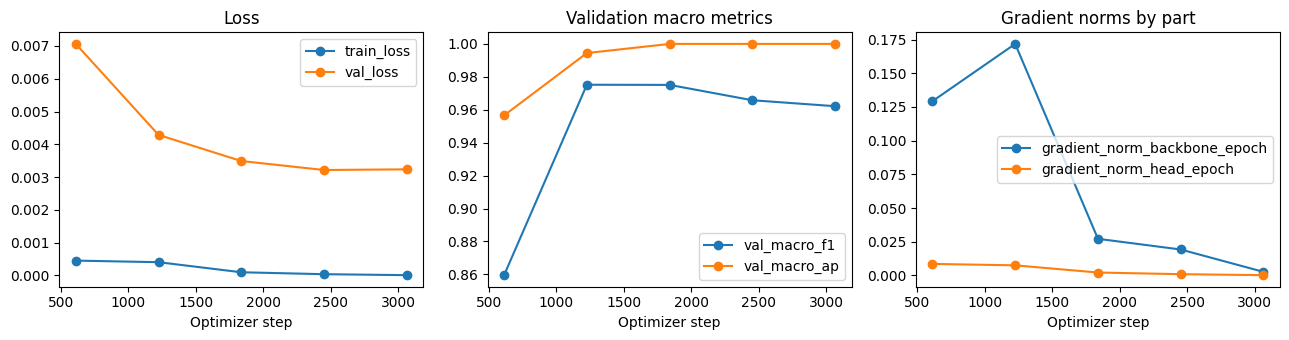

Saved curves: /content/ai301/artifacts/convnext_standard_fold0_seed42_20261018_full1/curves.png


Saved gradient flow: /content/ai301/artifacts/convnext_standard_fold0_seed42_20261018_full1/gradient_flow.png


In [ ]:
if RUN_TRAINING:
    import csv
    import matplotlib.pyplot as plt

    with (Path(logger.log_dir) / 'metrics.csv').open(newline='') as file:
        history = list(csv.DictReader(file))
    figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    for axis, names, title in zip(
        axes,
        (('train_loss', 'val_loss'), ('val_macro_f1', 'val_macro_ap'), ('gradient_norm_backbone_epoch', 'gradient_norm_head_epoch')),
        ('Loss', 'Validation macro metrics', 'Gradient norms by part'),
    ):
        for name in names:
            points = [(int(row['step']), float(row[name])) for row in history if row.get(name) not in (None, '')]
            if points:
                axis.plot(*zip(*points), marker='o', label=name)
        axis.set(title=title, xlabel='Optimizer step')
        if axis.lines:
            axis.legend()
    figure.tight_layout()
    curves_path = run_dir / 'curves.png'
    figure.savefig(curves_path, dpi=140)
    plt.show()
    print('Saved curves:', curves_path)
    with record_failures(run_dir, failure_configuration, 'gradient_flow', backup_failure):
        gradient_flow_path = plot_gradient_flow(run_dir / 'diagnostics' / 'layer_gradients.csv', run_dir / 'gradient_flow.png')
    print('Saved gradient flow:', gradient_flow_path)
    if drive_backup is not None:
        drive_backup.save_results([curves_path, gradient_flow_path])
else:
    print('No training curves to plot.')

## Evaluate a completed fold, not the smoke test

When the runtime gate permits the full run, reload the *best validation checkpoint*, not simply the last epoch, and predict all 2,452 fold-0 images in their saved order. To evaluate later without retraining, set both `STAGE2_EVAL_CHECKPOINT` and `STAGE2_EVAL_RUN_RECORD`, plus a fresh `STAGE2_RUN_ID`. The notebook verifies the checkpoint hash and original recipe, then writes a separate evaluation record and probability CSV under `artifacts/<run-id>_evaluation/`; it does not rewrite the training record. Keep the original pretrained weights and head file available: the notebook rebuilds the model before loading the checkpoint.

Report macro and per-label F1 at the fixed 0.25 threshold, average precision (which does not use that threshold), and F1 at 0.5 for context. The 0.25 threshold and checkpoint-selection metric are held fixed across the head-only and fine-tuned runs. A stopped timing probe or smoke test has no reportable quality score.


In [ ]:
with record_failures(run_dir, failure_configuration, 'evaluation', backup_failure):
    if EVAL_CHECKPOINT or (RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded):
        checkpoint_path = Path(EVAL_CHECKPOINT).resolve() if EVAL_CHECKPOINT else Path(checkpoint.best_model_path)
        if not checkpoint_path.is_file():
            raise FileNotFoundError(f'Missing full checkpoint: {checkpoint_path}')
        best_module = FineTuneClassifier.load_from_checkpoint(
            checkpoint_path, network=network, backbone_lr=BACKBONE_LR,
            head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY, threshold=THRESHOLD,
        )
        prediction_started = time.perf_counter()
        predicted_ids, validation_probabilities = predict_probabilities(best_module, validation_loader, DEVICE)
        prediction_seconds = time.perf_counter() - prediction_started
        if predicted_ids != [row['image_id'] for row in validation_rows]:
            raise ValueError('Validation loader changed image order.')
        validation_targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in validation_rows])
        metrics = score_probabilities(validation_targets, validation_probabilities, THRESHOLD)
        diagnostic_metrics = score_probabilities(validation_targets, validation_probabilities, 0.5)
        print('Fold-0 metrics:', metrics)
        print('F1 at 0.5:', {'macro_f1': diagnostic_metrics['macro_f1'], 'per_label_f1': diagnostic_metrics['per_label_f1']})
    else:
        print('Full-fold evaluation skipped; smoke and timing-gate scores are not results.')


Fold-0 metrics: {'threshold': 0.25, 'macro_f1': 0.9751849358283667, 'per_label_f1': {'Cat': 0.9965568125922283, 'Dog': 0.9970149253731343, 'Moris': 1.0, 'Motya': 0.9411764705882353, 'Biatrix': 0.9411764705882353}, 'macro_ap': 0.9944286914422321, 'per_label_ap': {'Cat': 0.9999740760019973, 'Dog': 0.9999471589869415, 'Moris': 0.9999999999999999, 'Motya': 0.9722222222222223, 'Biatrix': 1.0}}
F1 at 0.5: {'macro_f1': 0.9750861717351178, 'per_label_f1': {'Cat': 0.9960629921259843, 'Dog': 0.9970149253731343, 'Moris': 1.0, 'Motya': 0.9411764705882353, 'Biatrix': 0.9411764705882353}}


## Inspect where the model looks

After a complete evaluation, make one GradCAM overlay for the first positive validation image of each label. The examples are fixed by fold order before looking at predictions; they are illustrations, not evidence that the model learned the right cue. Layer-gradient measurements are saved separately during training.

In [ ]:
gradcam_paths = []
with record_failures(run_dir, failure_configuration, 'gradcam', backup_failure):
    if BUILD_GRADCAM and (EVAL_CHECKPOINT or (RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded)):
        import matplotlib.pyplot as plt
        from stage2.gradcam import gradcam_map

        output_dir = run_dir / 'gradcam'
        output_dir.mkdir(parents=True, exist_ok=True)
        best_module.to(DEVICE).eval()
        mean = torch.tensor(preprocessing['mean'])[:, None, None]
        std = torch.tensor(preprocessing['std'])[:, None, None]
        for label in LABEL_COLUMNS:
            index = next(i for i, row in enumerate(validation_rows) if row[label] == '1')
            image_id, normalized_image, _ = validation_data[index]
            heatmap = gradcam_map(best_module, normalized_image.unsqueeze(0).to(DEVICE), best_module.network.stages[-1], LABEL_COLUMNS.index(label)).cpu()
            display_image = (normalized_image * std + mean).clamp(0, 1).permute(1, 2, 0)
            figure, axis = plt.subplots(figsize=(5, 5))
            axis.imshow(display_image)
            axis.imshow(heatmap, cmap='magma', alpha=0.45, vmin=0, vmax=1)
            axis.set(title=f'{label}: {image_id}', xticks=[], yticks=[])
            path = output_dir / f'{label.lower()}_{image_id}.png'
            if path.exists():
                plt.close(figure)
                raise FileExistsError(f'Refusing to overwrite {path}')
            figure.savefig(path, dpi=140, bbox_inches='tight')
            plt.close(figure)
            gradcam_paths.append(path)
            print('Saved GradCAM:', path)
        if RUN_TRAINING and drive_backup is not None:
            drive_backup.save_results(gradcam_paths)
    else:
        print('GradCAM skipped.')


Saved GradCAM: /content/ai301/artifacts/convnext_standard_fold0_seed42_20261018_full1/gradcam/cat_116d851cb24f39d28f719a743d10df086eb2c793.png


Saved GradCAM: /content/ai301/artifacts/convnext_standard_fold0_seed42_20261018_full1/gradcam/dog_e6aea26b070dfe40f6a6121538f00cab344dc03a.png


Saved GradCAM: /content/ai301/artifacts/convnext_standard_fold0_seed42_20261018_full1/gradcam/moris_055cb6e1fe1eb7fc077bd98717851ae53de3113c.png


Saved GradCAM: /content/ai301/artifacts/convnext_standard_fold0_seed42_20261018_full1/gradcam/motya_cfbc890562e329131f546b43be873f41a06ad195.png


Saved GradCAM: /content/ai301/artifacts/convnext_standard_fold0_seed42_20261018_full1/gradcam/biatrix_14ababeb09beeaf8dd430e851e671475ab15fc46.png


In [ ]:
with record_failures(run_dir, failure_configuration, 'results', backup_failure):
    if EVAL_CHECKPOINT or (RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded):
        result_dir = run_dir if EVAL_CHECKPOINT else ROOT / 'experiments' / '01_convnext_standard' / 'results'
        probability_path = result_dir / f'{RUN_ID}_val.csv'
        record_path = result_dir / f'{RUN_ID}.json'
        for path in (probability_path, record_path):
            if path.exists():
                raise FileExistsError(f'Refusing to overwrite {path}')
        git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True, check=True).stdout.strip() if (ROOT / '.git').exists() else None
        source_files = (ROOT / 'notebooks' / '06_convnext_standard.ipynb', ROOT / 'stage2' / 'experiment.py', ROOT / 'stage2' / 'train.py', ROOT / 'stage2' / 'finetune.py', ROOT / 'stage2' / 'run_records.py', ROOT / 'stage2' / 'diagnostics.py', ROOT / 'stage2' / 'gradcam.py')
        source_sha256 = {str(path.relative_to(ROOT)): file_sha256(path) for path in source_files}
        if EVAL_CHECKPOINT:
            record = {**source_run_record, 'run_id': RUN_ID, 'status': 'evaluated',
                      'source_run_id': source_run_record['run_id'], 'source_run_record': str(Path(EVAL_RUN_RECORD).resolve()),
                      'source_run_record_sha256': file_sha256(Path(EVAL_RUN_RECORD)),
                      'evaluation': {'git_commit': git_commit, 'source_sha256': source_sha256, 'device': str(DEVICE),
                                     'prediction_seconds': prediction_seconds,
                                     'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__}},
                      'metrics': {**metrics, 'macro_f1_at_0_5': diagnostic_metrics['macro_f1'], 'per_label_f1_at_0_5': diagnostic_metrics['per_label_f1']},
                      'artifacts': {**source_run_record['artifacts'], 'validation_probabilities_csv': str(probability_path.relative_to(ROOT)),
                                    'evaluated_checkpoint': str(checkpoint_path), 'gradcam_images': [str(path.relative_to(ROOT)) for path in gradcam_paths]}}
        else:
            record = {**run_configuration, 'run_id': RUN_ID, 'experiment': '01_convnext_standard', 'status': 'completed',
                      'git_commit': git_commit, 'source_sha256': source_sha256,
                      'training': {**run_configuration['training'], 'epochs_completed': trainer.fit_loop.epoch_progress.current.completed},
                      'hardware': diagnostics.memory,
                      'trainable_parameters': sum(p.numel() for p in network.parameters() if p.requires_grad),
                      'metrics': {**metrics, 'macro_f1_at_0_5': diagnostic_metrics['macro_f1'], 'per_label_f1_at_0_5': diagnostic_metrics['per_label_f1']},
                      'timings': {'training_and_validation_seconds': training_seconds, 'epoch_seconds': checkpoint.epoch_seconds, 'first_epoch_projected_seconds': checkpoint.projected_seconds, 'best_checkpoint_prediction_seconds': prediction_seconds},
                      'artifacts': {'validation_probabilities_csv': str(probability_path.relative_to(ROOT)), 'best_checkpoint_local': str(checkpoint_path.relative_to(ROOT)),
                                    'best_checkpoint_sha256': file_sha256(checkpoint_path), 'curves_csv': str((Path(logger.log_dir) / 'metrics.csv').relative_to(ROOT)),
                                    'layer_gradients_csv': str((run_dir / 'diagnostics' / 'layer_gradients.csv').relative_to(ROOT)), 'gradient_flow_png': str(gradient_flow_path.relative_to(ROOT)),
                                    'memory_json': str((run_dir / 'diagnostics' / 'memory.json').relative_to(ROOT)), 'gradcam_images': [str(path.relative_to(ROOT)) for path in gradcam_paths],
                                    'drive_backup_dir': str(drive_backup.drive_dir) if drive_backup is not None else None},
                      'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__},
                      'telemetry': {'wandb_enabled': USE_WANDB, 'wandb_mode': WANDB_MODE if USE_WANDB else None, 'wandb_project': WANDB_PROJECT if USE_WANDB else None, 'wandb_run_id': wandb_logger.version if wandb_logger is not None else None, 'model_upload': False},
                      'public_leaderboard_score': None, 'error': None}
        write_probabilities(probability_path, predicted_ids, validation_probabilities, VALIDATION_FOLD)
        write_run_record(record_path, record)
        print('Saved:', record_path, probability_path, sep='\n')
        if RUN_TRAINING and drive_backup is not None:
            drive_backup.save_results([record_path, probability_path])
    else:
        print('No full-run artifacts written.')


Saved:
/content/ai301/experiments/01_convnext_standard/results/convnext_standard_fold0_seed42_20261018_full1.json
/content/ai301/experiments/01_convnext_standard/results/convnext_standard_fold0_seed42_20261018_full1_val.csv


## Make a submission file, if we want one

Only do this after reviewing the validation result. With `BUILD_SUBMISSION=True`, the notebook predicts the test images and writes a CSV in the same order as `sample_submission.csv`. It checks the IDs and column names before writing.

This creates a local file; it does not upload anything. Kaggle submission and recording the public score are separate manual steps. `SUBMIT_TO_KAGGLE` remains false and has no submission code attached to it.

In [ ]:
if BUILD_SUBMISSION:
    if not (EVAL_CHECKPOINT or (RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded)):
        raise ValueError('Build a submission only after a complete fold run.')
    test_data = ImageDataset(test_rows, DATA_DIR / 'test', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
    test_loader = DataLoader(test_data, shuffle=False, **loader_options)
    test_ids, test_probabilities = predict_probabilities(best_module, test_loader, DEVICE)
    submission_rows = form_submission(DATA_DIR / 'sample_submission.csv', test_ids, test_probabilities, THRESHOLD)
    submission_dir = run_dir
    submission_path = submission_dir / f'{RUN_ID}_submission.csv'
    write_submission(submission_path, submission_rows)
    print('CSV ready for manual review:', submission_path)
    if RUN_TRAINING and drive_backup is not None:
        drive_backup.save_results([submission_path])
else:
    print('No submission CSV built or uploaded.')

No submission CSV built or uploaded.


## Read the comparison carefully

Compare this run only with the head-only fold-0 result on the same images and threshold (macro F1 0.93577). Look at named-pet scores, loss curves, layer-gradient flow, GradCAM overlays, and elapsed time as well as the aggregate score. If the new model does not improve, keep the result: it tells us whether full fine-tuning was worth its cost. The old five-fold 0.957 and public 0.92922 numbers answer different questions. A final claim needs a broader evaluation and the matched custom-block comparison.

Before leaving Colab, preserve the CLI-generated output-bearing notebook alongside the run JSON and CSV. Drive holds the training artifacts when backup is enabled, but this notebook's displayed outputs are a separate record. Do not claim a public leaderboard improvement until a reviewed submission has actually been uploaded and scored.
